<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load the camera image as a float matrix
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


In [7]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print('U:', U.shape, 's:', s.shape, 'Vt:', Vt.shape)

A_back = U @ np.diag(s) @ Vt
print('Rebuilt correctly?', np.allclose(A, A_back))
print('Largest error:', np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.503952600818593e-11


First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


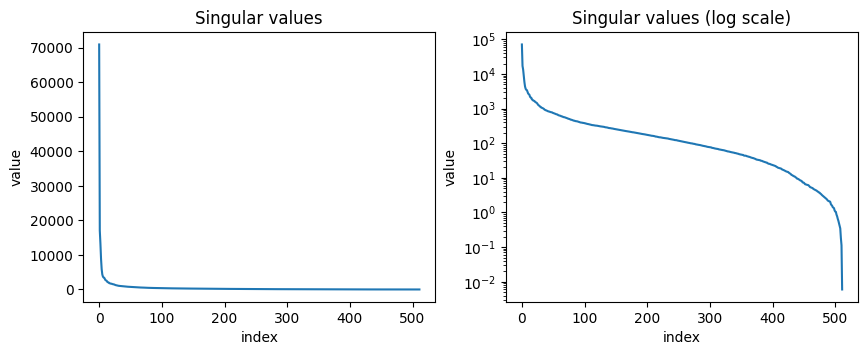

In [8]:
print('First five:', np.round(s[:5], 1))
print('50th, 200th, last:', round(s[49], 1), round(s[199], 1), round(s[-1], 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title='Singular values', xlabel='index', ylabel='value')

ax2.semilogy(s)
ax2.set(title='Singular values (log scale)', xlabel='index', ylabel='value')
plt.show()

In [9]:
def rank_k_approx(A, k):
  """Return the rank-k SVD approximation of A."""
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

In [10]:
print('rank of A_10:', np.linalg.matrix_rank(rank_k_approx(A, 10)))
print('k = 512 gives A back?', np.allclose(rank_k_approx(A, 512), A))

stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print('singular values of stripes:', np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


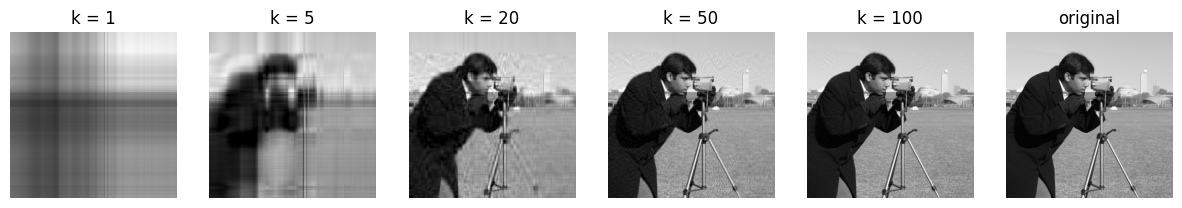

In [11]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')

axes[-1].imshow(A, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')
plt.show()

In [12]:
# Exercise 1: Finding singular values via eigenvalues of M^T @ M
m = np.array([[3, 0], [4, 5]])
eigvals_m = np.linalg.eigvals(m)
print('Eigenvalues of m:', eigvals_m)

mt_m = m.T @ m
eigvals_mt_m = np.linalg.eigvals(mt_m)
singular_values_from_eig = np.sqrt(np.sort(eigvals_mt_m)[::-1])
print('Singular values calculated from eigenvalues of m.T @ m:', singular_values_from_eig)

direct_singular_values = np.linalg.svd(m, compute_uv=False)
print('Direct singular values from SVD:', direct_singular_values)

Eigenvalues of m: [5. 3.]
Singular values calculated from eigenvalues of m.T @ m: [6.70820393 2.23606798]
Direct singular values from SVD: [6.70820393 2.23606798]


In [13]:
print(np.linalg.norm(A - rank_k_approx(A, 20)))
print(np.sqrt(np.sum(s[20:]**2)))

7699.9091419681245
7699.9091419681245


In [14]:
import os
import subprocess
import sys
USER = 'tzbdragon'
REPO = 'LinAlg344TZB'
if os.path.exists(REPO):
  subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
  subprocess.run(
  ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
  check=True)
sys.path.insert(0, f'{REPO}/src')

Shape: (4016, 6016)
Data type: float64


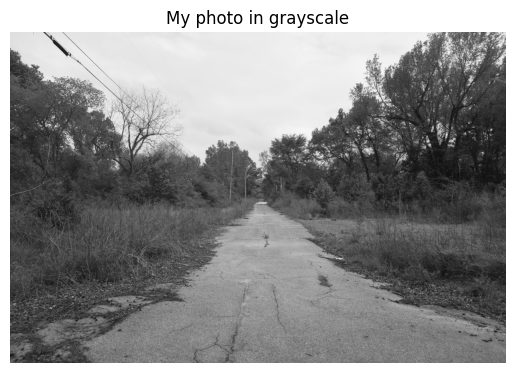

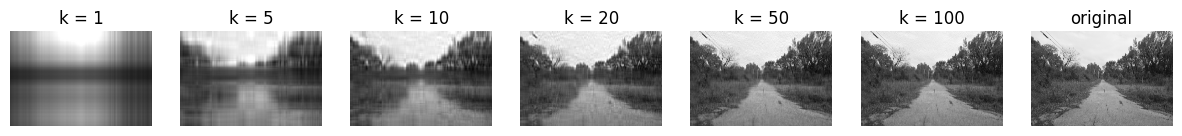

In [16]:
from google.colab import files
from PIL import Image
# Convert the image to grayscale ('L') to make it a 2D matrix
P = np.array(Image.open(f"{REPO}/data/TZB_7471.JPG").convert('L')).astype(float)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

ks = [1, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Pk = np.clip(rank_k_approx(P, k), 0, 255)
  ax.imshow(Pk, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')

axes[-1].imshow(P, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')
plt.show()

It's Shockingly recognizable at k = 20, and still discernable at k = 10. This is almost certainly because it is an image of a landscape. Eveny though it's 6K by 4K there just isn't really any data to be captured so it holds up better under compression

### Exercise Answers

#### **Exercise 1**
Simultaneous sign changes in $u_1$ and $v_1$ leave $u_1 v_1^T$ unchanged because of basic scalar multiplication:
$$(-u_1)(-v_1)^T = (-1)(1) u_1 v_1^T = u_1 v_1^T$$
Both negative signs cancel each other out, yielding the exact same rank-1 matrix.

#### **Exercise 2**
Yes, the Frobenius norm of the difference $\|A - A_k\|_F$ matches the square root of the sum of the squared singular values from index $k$ onwards:
$$\|A - A_{20}\|_F = \sqrt{\sum_{i=20}^{511} \sigma_i^2}$$
The Python slice begins at `s[20:]` because Python uses 0-based indexing. Thus, `s[20]` represents the 21st singular value (which is $\sigma_{21}$). Since a rank-20 approximation ($A_{20}$) keeps the first 20 singular values (indices $0$ to $19$), the error or remainder term starts precisely with index $20$ ($\sigma_{21}$).

#### **Exercise 3**
Using the image `TZB_7471.JPG` loaded from the repository, the image becomes shockingly recognizable even at $k = 20$, and is still quite discernible at $k = 10$.

Because this photograph is a landscape with open skies, distant trees, and a road, it contains large continuous regions of similar gradients and fewer ultra-sharp high-frequency details. This low-frequency structure allows the main features of the image to hold up exceptionally well under low-rank SVD compression compared to the camera image, which has sharp human silhouettes, tripod lines, and buildings that require more high-frequency information to reconstruct clearly.